<a href="https://colab.research.google.com/github/eojin22/ESAA/blob/main/OB_WEEK10_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5.2 합성곱 신경망 맛보기

- fashion_mnis 데이터셋을 사용해 합성곱 신경망 직접 구현

**fashion_mnist 데이터셋**
- 예제 데이터(운동화, 셔츠, 샌들 같은 작은 이미지의 모음)

- 0~9까지 정수값은 이미지의 클래스를 나타냄

In [1]:
# 라이브러리 호출
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms # 데이터 전처리를 위해 사용하는 라이브러리
from torch.utils.data import Dataset, DataLoader

In [2]:
# CPU 혹은 GPU 장치 확인
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [3]:
from IPython.testing import test
# fashion_mnist 데이터셋 내려받기
train_dataset = torchvision.datasets.FashionMNIST("../chap05/data", download = True,
                                                  transform = transforms.Compose([transforms.ToTensor()]))
test_dataset = torchvision.datasets.FashionMNIST("../chap05/data", download = True,
                                                  transform = transforms.Compose([transforms.ToTensor()]))

100%|██████████| 26.4M/26.4M [00:01<00:00, 21.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 349kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.29MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.7MB/s]


파라미터
- 1st: 내려받을 위치 지정
- download: True일 때 첫 번째 파라미터 위치에 데이터셋 있는지 확인하고 내려받음
- transform: 이미지를 텐서(0~1)로 변경

In [4]:
# fashion_mnist 데이터를 데이터로더에 전달

train_loader = torch.utils.data.DataLoader(train_dataset,
                                           batch_size = 100)
test_loader = torch.utils.data.DataLoader(test_dataset,
                                          batch_size = 100)

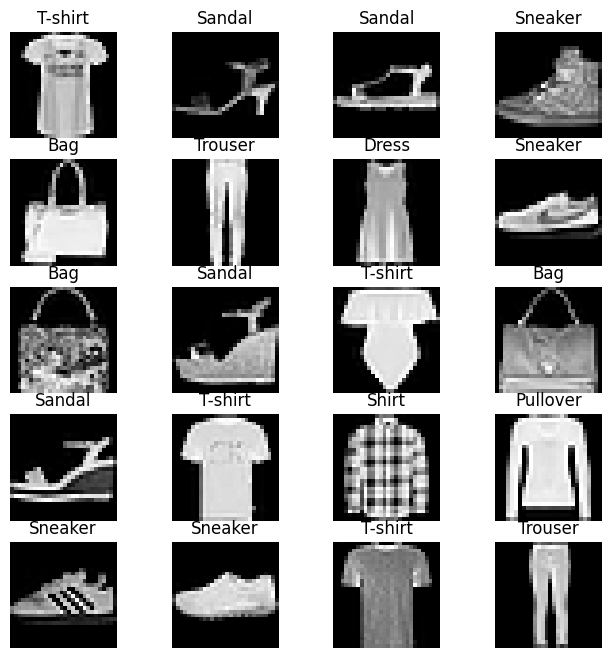

In [5]:
# 분류에 사용될 클래스 정의

labels_map = { 0: 'T-shirt', 1:'Trouser', 2:'Pullover', 3:'Dress', 4:'Coat', 5:'Sandal',
              6:'Shirt', 7:'Sneaker', 8:'Bag', 9:'Ankle Boot'} # 열 개의 클래스

fig = plt.figure(figsize=(8,8)); # 출력할 이미지의 가로세로 길이로 단위는 inch
columns = 4;
rows = 5;
for i in range(1, columns*rows + 1):
  img_xy = np.random.randint(len(train_dataset));
  img = train_dataset[img_xy][0][0,:,:]
  fig.add_subplot(rows, columns, i)
  plt.title(labels_map[train_dataset[img_xy][1]])
  plt.axis('off')
  plt.imshow(img, cmap='gray')
plt.show()  # 20개의 이미지 데이터를 시각적으로 표현

- np.random.randint() : 이산 형 분포를 갖는 데이터에서 무작위 표본을 추출할 때 시용

- img = train_dataset[img_xy][0][0,:,:] 의미
해당 index의 요소 값을 가져오겠다는 뜻

In [6]:
# 심층 신경망 모델 생성

class FashionDNN(nn.Module):
  def __init__(self):  #1
    super(FashionDNN, self).__init__()
    self.fc1 = nn.Linear(in_features=784, out_features=256)  #2
    self.drop = nn.Dropout(0.25)  #3
    self.fc2 = nn.Linear(in_features=256, out_features=128)
    self.fc3 = nn.Linear(in_features=128, out_features=10)

  def forward(self, input_data):  #4
    out = input_data.view(-1, 784)  #5
    out = F.relu(self.fc1(out))  #6
    out = self.drop(out)
    out = F.relu(self.fc2(out))
    out = self.fc3(out)
    return out

1. 클래스 형태의 모델은 항상 torch.nn.Module을 상속받음
- init(): 객체가 갖는 속성 값 초기화하는 역할, 객체가 생성될 때 자동으로 호출됨

2. nn: 딥러닝 모델 구성에 필요한 모듈이 모여 있는 패키지
- Linear: 단순 선형 회귀 모델을 만들 때 사용

3. torch.nn.Dropout(p): p만큼의 비율로 텐서의 값이 0이 됨, 0이 되지 않는 값들은 기존 값에 (1/(1-p))만큼 곱해져 커짐

4. forward(): 모델이 학습 데이터를 입력받아서 순전파 학습을 진행시킴, 반드시 forward라는 이름의 함수여야 함

5. view: 넘파이의 reshape와 같은 역할, 텐서의 shape를 변경해줌

6. 활성화 함수를 지정하는 방법
- F.relu(): forward() 함수에서 정의
- nn.ReLu(): init() 함수에서 정의

In [7]:
# 심층 신경망에서 필요한 파라미터 정의
learning_rate = 0.001;
model = FashionDNN();
model.to(device)

criterion = nn.CrossEntropyLoss(); # 분류 문제에서 사용하는 손실 함수
optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate);  #1
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


- 옵티마이저를 위한 경사하강법은 Adam 사용

In [8]:
num_epochs = 5
count = 0

loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)

      train = Variable(images.view(100, 1, 28, 28))
      labels = Variable(labels)

      outputs = model(train) # 학습 데이터를 모델에 적용
      loss = criterion(outputs, labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      count += 1

      if not (count % 50): # count를 50으로 나누었을 때 나머지가 0이 아니라면 실행
        total = 0
        correct = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            labels_list.append(labels)
            test = Variable(images.view(100, 1, 28, 28))
            outputs = model(test)
            predictions = torch.max(outputs, 1)[1].to(device)
            predictions_list.append(predictions)
            correct += (predictions == labels).sum()
            total += len(labels)

        accuracy = correct * 100 / total
        loss_list.append(loss. data)
        iteration_list.append(count)
        accuracy_list.append(accuracy)

      if not (count % 500):
         print("Iteration: {}, Loss: {}, Accuracy: {}%" .format(count, loss.data,
                                                             accuracy))

Iteration: 500, Loss: 0.5517702698707581, Accuracy: 84.80999755859375%
Iteration: 1000, Loss: 0.5739211440086365, Accuracy: 85.71666717529297%
Iteration: 1500, Loss: 0.3566533625125885, Accuracy: 86.30999755859375%
Iteration: 2000, Loss: 0.3747817277908325, Accuracy: 87.48833465576172%
Iteration: 2500, Loss: 0.2957344949245453, Accuracy: 87.84666442871094%
Iteration: 3000, Loss: 0.2824638783931732, Accuracy: 88.67833709716797%


In [9]:
# 합성곱 네트워크 생성
class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(in_features=64*6*6, out_features=600)
        self.drop = nn.Dropout(0.25)
        self.fc2 = nn.Linear(in_features=600, out_features=120)
        self.fc3 = nn.Linear(in_features=120, out_features=10)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        out = self.drop(out)
        out = self.fc2(out)
        out = self.fc3(out)
        return out

> Conv2d 계층에서의 출력 크기 구하는 공식

출력 크기 = (W-F+2P)/S+1

- W: 입력 데이터의 크기(input_volume_size)
- F: 커널 크기(kernel_size)
- P: 패딩 크기 (padding_size)
- S: 스트라이드(strides)

> MaxPool2d 계층에서의 출력 크기 구하는 공식

출력 크기 =IF/F

- IF: 입력 필터의 크기
- F: 커널 크기

In [10]:
# 합성곱 네트워크를 위한 파라미터 정의
learning_rate = 0.001;
model = FashionCNN();
model.to(device)

criterion = nn.CrossEntropyLoss();
optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate);
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


In [ ]:
# 모델 학습 및 성능 평가
num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    train = Variable(images.view(100, 1, 28, 28))
    labels = Variable(labels)

    outputs = model(train)
    loss = criterion(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    count += 1

    if not(count % 50):
      total = 0
      correct = 0
      for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels_list.append(labels)
        test = Variable(images.view(100, 1, 28, 28))
        outputs = model(test)
        predictions = torch.max(outputs, 1)[1].to(device)
        predictions_list.append(predictions)
        correct += (predictions == labels).sum()
        total += len(labels)

      accuracy = correct * 100 / total
      loss_list.append(loss.data)
      iteration_list.append(count)
      accuracy_list.append(accuracy)

    if not(count % 500):
      print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data, accuracy))